In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [18]:
codes = pd.DataFrame({
    "RefSeq vs GENCODE": {"=":1113, "c":55, "e":4, "i":50, "j":689, "k":275,
                          "m":24, "n":15, "o":18, "p":2, "u":38, "x":29},
    "GENCODE vs RefSeq": {"=":1243, "c":195, "e":22, "i":170, "j":5448, "k":129,
                          "m":103, "n":121, "o":203, "p":9, "u":389, "x":303, "y":45},
}).fillna(0)
codes

,RefSeq vs GENCODE,GENCODE vs RefSeq
=,1113.0,1243
c,55.0,195
e,4.0,22
i,50.0,170
j,689.0,5448
k,275.0,129
m,24.0,103
n,15.0,121
o,18.0,203
p,2.0,9


In [19]:
codes.sum()

RefSeq vs GENCODE    2312.0
GENCODE vs RefSeq    8380.0
dtype: float64

In [20]:
levels = ["Base", "Exon", "Intron", "Intron chain", "Transcript", "Locus"]
rs_sens = [48.2, 37.1, 36.4, 11.6, 13.4, 46.8]
rs_prec = [60.6, 76.3, 84.4, 45.9, 48.1, 64.3]
gc_sens = [60.6, 76.8, 84.5, 45.9, 47.5, 62.4]
gc_prec = [48.2, 37.6, 36.4, 11.5, 13.1, 45.4]

In [21]:
missed_novel = pd.DataFrame({
    "RS vs GC missed": [29.4, 17.7, 36.5],
    "RS vs GC novel":  [9.7, 4.8, 12.7],
}, index=["Exons", "Introns", "Loci"])

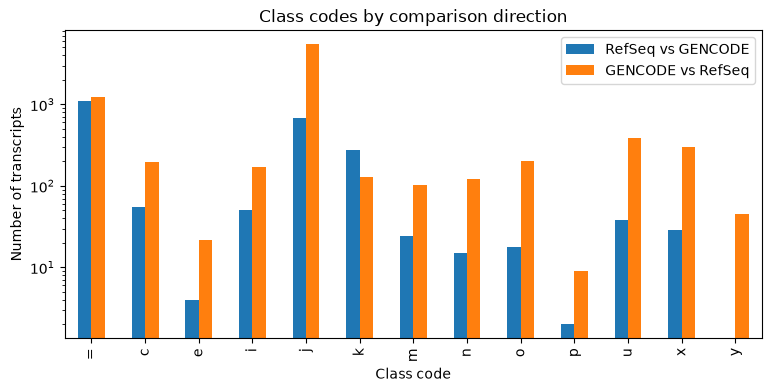

In [22]:
codes.plot(kind="bar", figsize=(9,4))
plt.ylabel("Number of transcripts")
plt.xlabel("Class code")
plt.title("Class codes by comparison direction")
plt.yscale("log")
plt.show()

This is a grouped bar chart (log-scaled y-axis) of the number of transcripts in each gffcompare class code. The Blue bars are RefSeq transcripts compared against GENCODE, where orange bars are GENCODE transcripts compared against RefSeq.

The most common class pretty much depends on which direction we're looking at. With RefSeq as the query, = (exact intron chain match) is largest at 1,113 of 2,312 transcripts. With GENCODE as the query, j (shares a splice junction but is a different isoform) is largest at 5,448 of 8,380. GENCODE also has 389 transcripts with no RefSeq overlap (u), compared with 38 RefSeq transcripts that have no GENCODE overlap.

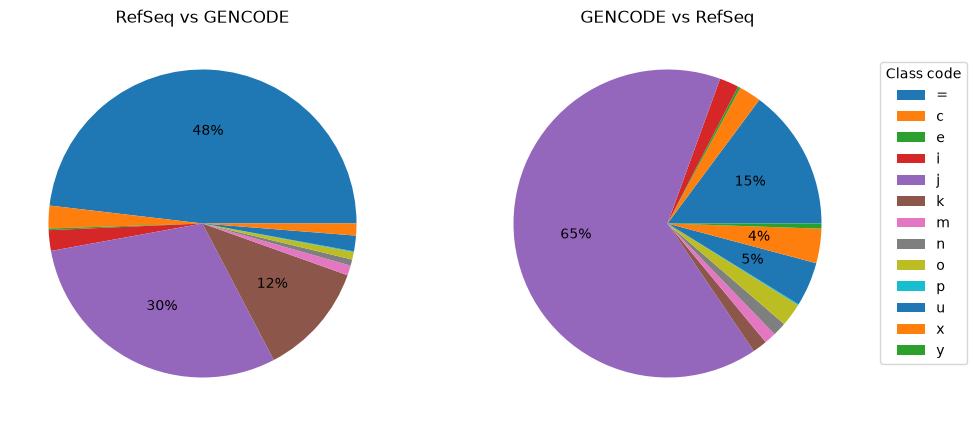

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(11,5))
for ax, col in zip(axes, codes.columns):
    ax.pie(codes[col], autopct=lambda p: f"{p:.0f}%" if p >= 3 else "")
    ax.set_title(col)
fig.legend(codes.index, loc="center right", title="Class code")
plt.show()

These are pie charts showing the proportion of query transcripts in each class code, with each chart showing a different comparison direction (ref vs gen or gen vs ref). The data are the same class code counts from Figure 1, but now as percentages.

We see here that 48.1% of RefSeq transcripts have an exact match in GENCODE, but only 14.8% of GENCODE transcripts have an exact match in RefSeq. Part of this gap probably comes from size, where GENCODE has 8,380 transcripts and RefSeq has 2,312, so at most about 28% of GENCODE transcripts could have a one-to-one RefSeq match. Most of the remaining GENCODE transcripts (65.0%) are j, alternative isoforms of genes RefSeq already annotates.

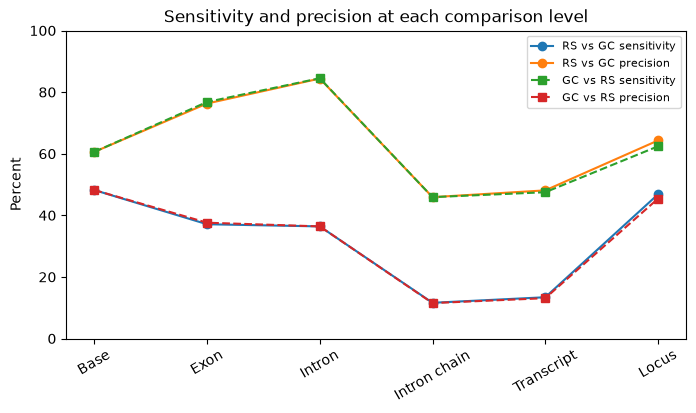

In [24]:
plt.figure(figsize=(8,4))
plt.plot(levels, rs_sens, marker="o", label="RS vs GC sensitivity")
plt.plot(levels, rs_prec, marker="o", label="RS vs GC precision")
plt.plot(levels, gc_sens, marker="s", linestyle="--", label="GC vs RS sensitivity")
plt.plot(levels, gc_prec, marker="s", linestyle="--", label="GC vs RS precision")
plt.ylabel("Percent"); plt.ylim(0, 100); plt.xticks(rotation=30)
plt.title("Sensitivity and precision at each comparison level")
plt.legend(fontsize=8); plt.show()

This is a line plot of gffcompare sensitivity and precision (%) at six comparison levels (x-axis), in the order gffcompare reports them, for both comparison directions. The values were taken from the sensitivity/precision tables

Here we see that all four lines drop at the intron chain and transcript levels and rise again at the locus level. We can see that the two annotations agree pretty nicely on which genes exist and where individual splice sites are, but not so much on the full exon-intron structure of each transcript.

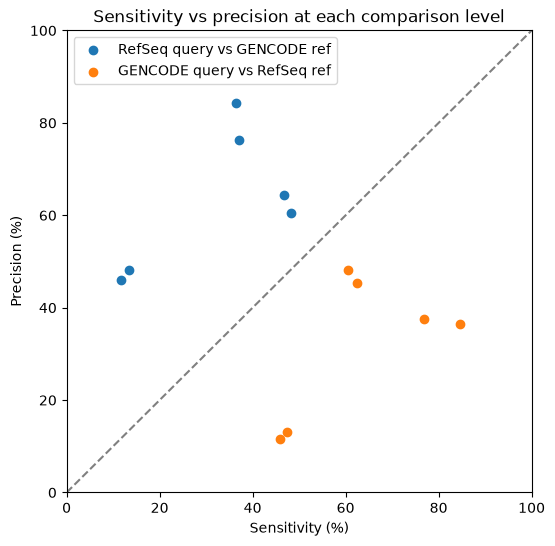

In [25]:
plt.figure(figsize=(6,6))
plt.scatter(rs_sens, rs_prec, label="RefSeq query vs GENCODE ref")
plt.scatter(gc_sens, gc_prec, label="GENCODE query vs RefSeq ref")
plt.plot([0,100], [0,100], "--", color="grey")
plt.xlim(0, 100); plt.ylim(0, 100)
plt.xlabel("Sensitivity (%)"); plt.ylabel("Precision (%)")
plt.title("Sensitivity vs precision at each comparison level")
plt.legend()
plt.show()

This is a scatter plot of sensitivity (x-axis) against precision (y-axis) for the same six levels as the other figures. The dashed line is y = x.

From this figure we can see that each orange point mirrors a blue point across the y=x line. Sensitivity with one annotation as reference equals precision with the other as reference, so the mirroring we see here bascially confirms that the two runs are consistent. Every RefSeq-first point sits above the line, meaning RefSeq features are found in GENCODE more often than GENCODE features are found in RefSeq.